In [3]:
import pandas as pd
import sklearn.model_selection
import sklearn.compose
import sklearn.preprocessing
import sklearn.metrics
import matplotlib.pyplot as plt
import seaborn as sns
import numpy as np
import random

# Data Collection

In [4]:
df = pd.read_csv("credit_score_train.csv")
df.head()

,ID,Customer_ID,Month,Name,Age,SSN,Occupation,Annual_Income,Monthly_Inhand_Salary,Num_Bank_Accounts,...,Credit_Mix,Outstanding_Debt,Credit_Utilization_Ratio,Credit_History_Age,Payment_of_Min_Amount,Total_EMI_per_month,Amount_invested_monthly,Payment_Behaviour,Monthly_Balance,Credit_Score
0,5634,3392,1,Aaron Maashoh,23.0,821000265.0,Scientist,19114.12,1824.843333,3.0,...,Good,809.98,26.822620,265.0,No,49.574949,21.46538,High_spent_Small_value_payments,312.494089,Good
1,5635,3392,2,Aaron Maashoh,23.0,821000265.0,Scientist,19114.12,1824.843333,3.0,...,Good,809.98,31.944960,266.0,No,49.574949,21.46538,Low_spent_Large_value_payments,284.629162,Good
2,5636,3392,3,Aaron Maashoh,23.0,821000265.0,Scientist,19114.12,1824.843333,3.0,...,Good,809.98,28.609352,267.0,No,49.574949,21.46538,Low_spent_Medium_value_payments,331.209863,Good
3,5637,3392,4,Aaron Maashoh,23.0,821000265.0,Scientist,19114.12,1824.843333,3.0,...,Good,809.98,31.377862,268.0,No,49.574949,21.46538,Low_spent_Small_value_payments,223.451310,Good
4,5638,3392,5,Aaron Maashoh,23.0,821000265.0,Scientist,19114.12,1824.843333,3.0,...,Good,809.98,24.797347,269.0,No,49.574949,21.46538,High_spent_Medium_value_payments,341.489231,Good


In [5]:
# Create new column
df["debt_to_income"] = df["Outstanding_Debt"] / df["Annual_Income"]

# Check the first few rows

print(df[["Outstanding_Debt", "Annual_Income", "debt_to_income"]].head())

   Outstanding_Debt  Annual_Income  debt_to_income
0            809.98       19114.12        0.042376
1            809.98       19114.12        0.042376
2            809.98       19114.12        0.042376
3            809.98       19114.12        0.042376
4            809.98       19114.12        0.042376


In [6]:
df.head()

,ID,Customer_ID,Month,Name,Age,SSN,Occupation,Annual_Income,Monthly_Inhand_Salary,Num_Bank_Accounts,...,Outstanding_Debt,Credit_Utilization_Ratio,Credit_History_Age,Payment_of_Min_Amount,Total_EMI_per_month,Amount_invested_monthly,Payment_Behaviour,Monthly_Balance,Credit_Score,debt_to_income
0,5634,3392,1,Aaron Maashoh,23.0,821000265.0,Scientist,19114.12,1824.843333,3.0,...,809.98,26.822620,265.0,No,49.574949,21.46538,High_spent_Small_value_payments,312.494089,Good,0.042376
1,5635,3392,2,Aaron Maashoh,23.0,821000265.0,Scientist,19114.12,1824.843333,3.0,...,809.98,31.944960,266.0,No,49.574949,21.46538,Low_spent_Large_value_payments,284.629162,Good,0.042376
2,5636,3392,3,Aaron Maashoh,23.0,821000265.0,Scientist,19114.12,1824.843333,3.0,...,809.98,28.609352,267.0,No,49.574949,21.46538,Low_spent_Medium_value_payments,331.209863,Good,0.042376
3,5637,3392,4,Aaron Maashoh,23.0,821000265.0,Scientist,19114.12,1824.843333,3.0,...,809.98,31.377862,268.0,No,49.574949,21.46538,Low_spent_Small_value_payments,223.451310,Good,0.042376
4,5638,3392,5,Aaron Maashoh,23.0,821000265.0,Scientist,19114.12,1824.843333,3.0,...,809.98,24.797347,269.0,No,49.574949,21.46538,High_spent_Medium_value_payments,341.489231,Good,0.042376


In [7]:
df = df.drop(columns=["Outstanding_Debt", "Annual_Income"])
print(df.head())

     ID  Customer_ID  Month           Name   Age          SSN Occupation  \
0  5634         3392      1  Aaron Maashoh  23.0  821000265.0  Scientist   
1  5635         3392      2  Aaron Maashoh  23.0  821000265.0  Scientist   
2  5636         3392      3  Aaron Maashoh  23.0  821000265.0  Scientist   
3  5637         3392      4  Aaron Maashoh  23.0  821000265.0  Scientist   
4  5638         3392      5  Aaron Maashoh  23.0  821000265.0  Scientist   

   Monthly_Inhand_Salary  Num_Bank_Accounts  Num_Credit_Card  ...  Credit_Mix  \
0            1824.843333                3.0              4.0  ...        Good   
1            1824.843333                3.0              4.0  ...        Good   
2            1824.843333                3.0              4.0  ...        Good   
3            1824.843333                3.0              4.0  ...        Good   
4            1824.843333                3.0              4.0  ...        Good   

   Credit_Utilization_Ratio Credit_History_Age  Payment_

In [8]:
df.head()

,ID,Customer_ID,Month,Name,Age,SSN,Occupation,Monthly_Inhand_Salary,Num_Bank_Accounts,Num_Credit_Card,...,Credit_Mix,Credit_Utilization_Ratio,Credit_History_Age,Payment_of_Min_Amount,Total_EMI_per_month,Amount_invested_monthly,Payment_Behaviour,Monthly_Balance,Credit_Score,debt_to_income
0,5634,3392,1,Aaron Maashoh,23.0,821000265.0,Scientist,1824.843333,3.0,4.0,...,Good,26.822620,265.0,No,49.574949,21.46538,High_spent_Small_value_payments,312.494089,Good,0.042376
1,5635,3392,2,Aaron Maashoh,23.0,821000265.0,Scientist,1824.843333,3.0,4.0,...,Good,31.944960,266.0,No,49.574949,21.46538,Low_spent_Large_value_payments,284.629162,Good,0.042376
2,5636,3392,3,Aaron Maashoh,23.0,821000265.0,Scientist,1824.843333,3.0,4.0,...,Good,28.609352,267.0,No,49.574949,21.46538,Low_spent_Medium_value_payments,331.209863,Good,0.042376
3,5637,3392,4,Aaron Maashoh,23.0,821000265.0,Scientist,1824.843333,3.0,4.0,...,Good,31.377862,268.0,No,49.574949,21.46538,Low_spent_Small_value_payments,223.451310,Good,0.042376
4,5638,3392,5,Aaron Maashoh,23.0,821000265.0,Scientist,1824.843333,3.0,4.0,...,Good,24.797347,269.0,No,49.574949,21.46538,High_spent_Medium_value_payments,341.489231,Good,0.042376


In [9]:
df_train, df_test = sklearn.model_selection.train_test_split(df, test_size=0.3, random_state=42)

print("df size:", df.shape)
print("df_train size:", df_train.shape)
print("df_test size:", df_test.shape)

df size: (100000, 27)
df_train size: (70000, 27)
df_test size: (30000, 27)


# Data Exploration

In [10]:
df.dtypes

ID                            int64
Customer_ID                   int64
Month                         int64
Name                         object
Age                         float64
SSN                         float64
Occupation                   object
Monthly_Inhand_Salary       float64
Num_Bank_Accounts           float64
Num_Credit_Card             float64
Interest_Rate               float64
Num_of_Loan                 float64
Type_of_Loan                 object
Delay_from_due_date         float64
Num_of_Delayed_Payment      float64
Changed_Credit_Limit        float64
Num_Credit_Inquiries        float64
Credit_Mix                   object
Credit_Utilization_Ratio    float64
Credit_History_Age          float64
Payment_of_Min_Amount        object
Total_EMI_per_month         float64
Amount_invested_monthly     float64
Payment_Behaviour            object
Monthly_Balance             float64
Credit_Score                 object
debt_to_income              float64
dtype: object

In [11]:
df.describe()


,ID,Customer_ID,Month,Age,SSN,Monthly_Inhand_Salary,Num_Bank_Accounts,Num_Credit_Card,Interest_Rate,Num_of_Loan,Delay_from_due_date,Num_of_Delayed_Payment,Changed_Credit_Limit,Num_Credit_Inquiries,Credit_Utilization_Ratio,Credit_History_Age,Total_EMI_per_month,Amount_invested_monthly,Monthly_Balance,debt_to_income
count,100000.000000,100000.000000,100000.000000,100000.000000,1.000000e+05,100000.000000,100000.000000,100000.000000,100000.00000,100000.000000,100000.00000,100000.000000,100000.000000,100000.000000,100000.000000,100000.000000,100000.000000,100000.000000,100000.000000,100000.000000
mean,80631.500000,25982.666640,4.500000,33.316340,5.004617e+08,4197.270835,5.368820,5.533570,14.53208,3.532880,21.08141,13.313120,10.470323,5.798250,32.285173,221.220460,107.699208,55.101315,392.697586,0.060657
std,43301.486619,14340.543051,2.291299,10.764812,2.908267e+08,3186.432497,2.593314,2.067098,8.74133,2.446356,14.80456,6.237166,6.609481,3.867826,5.116875,99.680716,132.267056,39.006932,201.652719,0.087425
min,5634.000000,1006.000000,1.000000,14.000000,8.134900e+04,303.645417,0.000000,0.000000,1.00000,0.000000,0.00000,0.000000,0.500000,0.000000,20.000000,1.000000,0.000000,0.000000,0.007760,0.000003
25%,43132.750000,13664.500000,2.750000,24.000000,2.451686e+08,1626.594167,3.000000,4.000000,7.00000,2.000000,10.00000,9.000000,5.380000,3.000000,28.052567,144.000000,29.268886,27.959111,267.615983,0.009572
50%,80631.500000,25777.000000,4.500000,33.000000,5.006886e+08,3095.905000,5.000000,5.000000,13.00000,3.000000,18.00000,14.000000,9.400000,5.000000,32.305784,219.000000,66.462304,45.156550,333.865366,0.028250
75%,118130.250000,38385.000000,6.250000,42.000000,7.560027e+08,5957.715000,7.000000,7.000000,20.00000,5.000000,28.00000,18.000000,14.850000,8.000000,36.496663,302.000000,147.392573,71.295797,463.215683,0.069716
max,155629.000000,50999.000000,8.000000,56.000000,9.999934e+08,15204.633333,11.000000,11.000000,34.00000,9.000000,62.00000,25.000000,29.980000,17.000000,50.000000,404.000000,1779.103254,434.191089,1183.930696,0.683252


In [12]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 100000 entries, 0 to 99999
Data columns (total 27 columns):
 #   Column                    Non-Null Count   Dtype  
---  ------                    --------------   -----  
 0   ID                        100000 non-null  int64  
 1   Customer_ID               100000 non-null  int64  
 2   Month                     100000 non-null  int64  
 3   Name                      100000 non-null  object 
 4   Age                       100000 non-null  float64
 5   SSN                       100000 non-null  float64
 6   Occupation                100000 non-null  object 
 7   Monthly_Inhand_Salary     100000 non-null  float64
 8   Num_Bank_Accounts         100000 non-null  float64
 9   Num_Credit_Card           100000 non-null  float64
 10  Interest_Rate             100000 non-null  float64
 11  Num_of_Loan               100000 non-null  float64
 12  Type_of_Loan              100000 non-null  object 
 13  Delay_from_due_date       100000 non-null  fl

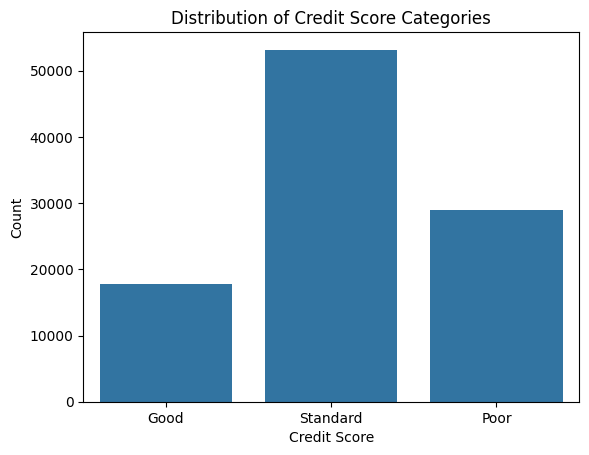

In [13]:


plt.figure()

sns.countplot(data=df, x='Credit_Score')

plt.title("Distribution of Credit Score Categories")
plt.xlabel("Credit Score")
plt.ylabel("Count")

plt.show()

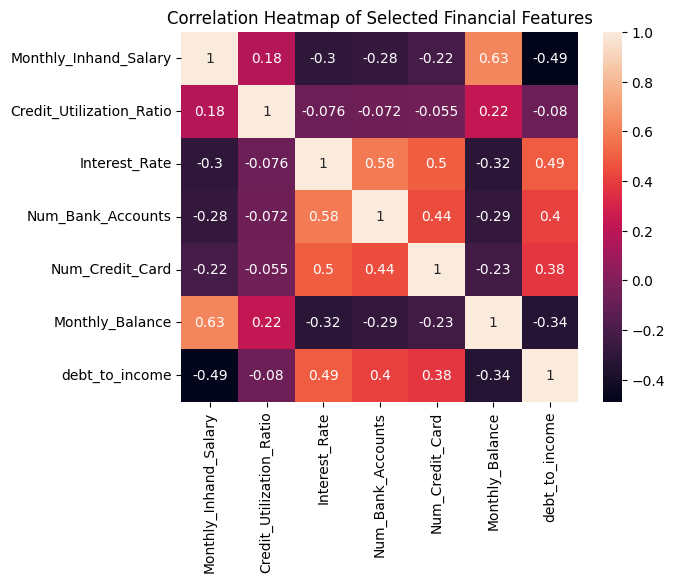

In [14]:
selected_columns = [
    'Monthly_Inhand_Salary',
    'Credit_Utilization_Ratio',
    'Interest_Rate',
    'Num_Bank_Accounts',
    'Num_Credit_Card',
    'Monthly_Balance',
    'debt_to_income'
]

corr_matrix = df[selected_columns].corr()

plt.figure()

sns.heatmap(corr_matrix, annot=True)

plt.title("Correlation Heatmap of Selected Financial Features")

plt.show()

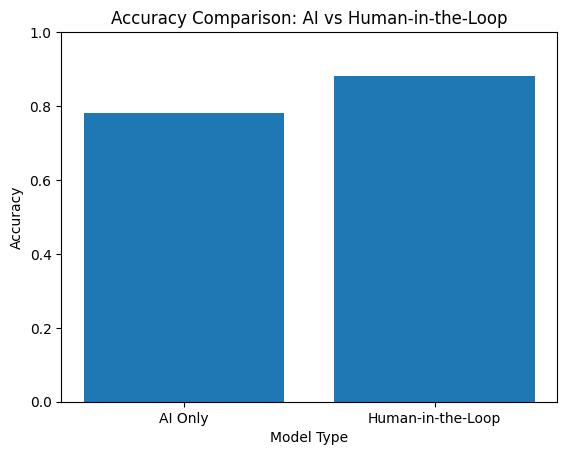

In [15]:
models = ['AI Only', 'Human-in-the-Loop']
accuracy = [0.78, 0.88]

plt.figure()

plt.bar(models, accuracy)

plt.title("Accuracy Comparison: AI vs Human-in-the-Loop")
plt.xlabel("Model Type")
plt.ylabel("Accuracy")

plt.ylim(0,1)

plt.show()

In [16]:
print("Dataset shape:", df.shape)

Dataset shape: (100000, 27)


# Data Processing

In [17]:
X = df.drop(columns=['ID','Customer_ID','Name','SSN','Credit_Score','Type_of_Loan','Payment_Behaviour'])
y = df['Credit_Score']

In [18]:
X.head()

,Month,Age,Occupation,Monthly_Inhand_Salary,Num_Bank_Accounts,Num_Credit_Card,Interest_Rate,Num_of_Loan,Delay_from_due_date,Num_of_Delayed_Payment,Changed_Credit_Limit,Num_Credit_Inquiries,Credit_Mix,Credit_Utilization_Ratio,Credit_History_Age,Payment_of_Min_Amount,Total_EMI_per_month,Amount_invested_monthly,Monthly_Balance,debt_to_income
0,1,23.0,Scientist,1824.843333,3.0,4.0,3.0,4.0,3.0,7.0,11.27,4.0,Good,26.822620,265.0,No,49.574949,21.46538,312.494089,0.042376
1,2,23.0,Scientist,1824.843333,3.0,4.0,3.0,4.0,3.0,4.0,11.27,4.0,Good,31.944960,266.0,No,49.574949,21.46538,284.629162,0.042376
2,3,23.0,Scientist,1824.843333,3.0,4.0,3.0,4.0,3.0,7.0,11.27,4.0,Good,28.609352,267.0,No,49.574949,21.46538,331.209863,0.042376
3,4,23.0,Scientist,1824.843333,3.0,4.0,3.0,4.0,5.0,4.0,6.27,4.0,Good,31.377862,268.0,No,49.574949,21.46538,223.451310,0.042376
4,5,23.0,Scientist,1824.843333,3.0,4.0,3.0,4.0,6.0,4.0,11.27,4.0,Good,24.797347,269.0,No,49.574949,21.46538,341.489231,0.042376


In [19]:
y.head()

0    Good
1    Good
2    Good
3    Good
4    Good
Name: Credit_Score, dtype: object

In [20]:
X.isna().sum()

Month                       0
Age                         0
Occupation                  0
Monthly_Inhand_Salary       0
Num_Bank_Accounts           0
Num_Credit_Card             0
Interest_Rate               0
Num_of_Loan                 0
Delay_from_due_date         0
Num_of_Delayed_Payment      0
Changed_Credit_Limit        0
Num_Credit_Inquiries        0
Credit_Mix                  0
Credit_Utilization_Ratio    0
Credit_History_Age          0
Payment_of_Min_Amount       0
Total_EMI_per_month         0
Amount_invested_monthly     0
Monthly_Balance             0
debt_to_income              0
dtype: int64

In [21]:
X.isna().sum()

Month                       0
Age                         0
Occupation                  0
Monthly_Inhand_Salary       0
Num_Bank_Accounts           0
Num_Credit_Card             0
Interest_Rate               0
Num_of_Loan                 0
Delay_from_due_date         0
Num_of_Delayed_Payment      0
Changed_Credit_Limit        0
Num_Credit_Inquiries        0
Credit_Mix                  0
Credit_Utilization_Ratio    0
Credit_History_Age          0
Payment_of_Min_Amount       0
Total_EMI_per_month         0
Amount_invested_monthly     0
Monthly_Balance             0
debt_to_income              0
dtype: int64

# Feature Engineering

In [22]:
from sklearn.model_selection import train_test_split

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.3, random_state=42
)

In [23]:
categorical_attributes = X_train.select_dtypes(include=["object"]).columns
numerical_attributes = X_train.select_dtypes(exclude=["object"]).columns

In [24]:
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import OneHotEncoder, StandardScaler

ct = ColumnTransformer(
    [
        ("onehot", OneHotEncoder(handle_unknown="ignore"), categorical_attributes),
        ("standard", StandardScaler(), numerical_attributes)
    ]
)

ct.fit(X_train)
X_train = ct.transform(X_train)
X_test = ct.transform(X_test)

print("x_train size:", X_train.shape)
print("x_test size:", X_test.shape)
print("y_train size:", y_train.shape)
print("y_test size:", y_test.shape)

x_train size: (70000, 38)
x_test size: (30000, 38)
y_train size: (70000,)
y_test size: (30000,)


In [25]:
feature_names = ct.get_feature_names_out()
X_train_df = pd.DataFrame(
    X_train,
    columns=feature_names
)

In [26]:
print(X_train_df.head())

   onehot__Occupation_Accountant  onehot__Occupation_Architect  \
0                            0.0                           0.0   
1                            1.0                           0.0   
2                            0.0                           0.0   
3                            0.0                           0.0   
4                            0.0                           0.0   

   onehot__Occupation_Developer  onehot__Occupation_Doctor  \
0                           0.0                        0.0   
1                           0.0                        0.0   
2                           0.0                        0.0   
3                           0.0                        0.0   
4                           0.0                        0.0   

   onehot__Occupation_Engineer  onehot__Occupation_Entrepreneur  \
0                          0.0                              0.0   
1                          0.0                              0.0   
2                          1.

# Model Training

In [57]:
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import accuracy_score
lr = LogisticRegression(
    random_state=42,
    max_iter=1000   # important to avoid convergence error
)

In [58]:
lr.fit(X_train, y_train)

LogisticRegression(max_iter=1000, random_state=42)

In [59]:
y_pred = lr.predict(X_test)
y_prob = lr.predict_proba(X_test)

In [60]:
print(y_prob)

[[0.39284072 0.12806908 0.4790902 ]
 [0.02443877 0.33123874 0.64432248]
 [0.64556555 0.10983837 0.24459608]
 ...
 [0.02308014 0.359109   0.61781087]
 [0.01296314 0.66272757 0.32430929]
 [0.00256936 0.71503553 0.28239511]]


In [61]:
print(y_pred)

['Standard' 'Standard' 'Good' ... 'Standard' 'Poor' 'Poor']


In [56]:
print("Accuracy:", accuracy_score(y_test, y_pred))

Accuracy: 0.6598666666666667


# Compute Confidence Scores

In [33]:
probs = lr.predict_proba(X_test)
confidence = np.max(probs, axis=1)
tau = 0.7



In [34]:
print(confidence)


[0.4790902  0.64432248 0.64556555 ... 0.61781087 0.66272757 0.71503553]


In [35]:
type(y_test)

pandas.core.series.Series

# Human Review Simulation (imperfect human)


In [36]:
np.random.seed(42)

human_accuracy = 0.95
y_final = []

if 'pandas' in str(type(y_test)):
    y_test_array = y_test.to_numpy()
else:
    y_test_array = y_test

if 'pandas' in str(type(y_pred)):
    y_pred_array = y_pred.to_numpy()
else:
    y_pred_array = y_pred

for i in range(len(y_test_array)):
    if confidence[i] < tau:
        if np.random.rand() < human_accuracy:
            y_final.append(y_test_array[i])
        else:
            y_final.append(y_pred_array[i])
    else:
        y_final.append(y_pred_array[i])

y_final = np.array(y_final)

In [55]:
from sklearn.metrics import accuracy_score

accuracy_ai = accuracy_score(y_test, y_pred)
accuracy_hitl = accuracy_score(y_test, y_final)

print("AI Only Accuracy:", accuracy_ai)
print("AI + Human Accuracy:", accuracy_hitl)

AI Only Accuracy: 0.6598666666666667
AI + Human Accuracy: 0.9804333333333334


AI only → 66.05% 
AI + Human-in-the-Loop → 83.16%
# Evaluate More Metrics


In [38]:
print("y_test shape:", y_test.shape)
print("y_pred shape:", y_pred.shape)

y_test shape: (30000,)
y_pred shape: (30000,)


In [54]:
from sklearn.metrics import accuracy_score, precision_score, recall_score, f1_score

# Convert to numpy arrays if needed
y_test_array = y_test.to_numpy() if 'pandas' in str(type(y_test)) else y_test
y_pred_array = y_pred.to_numpy() if 'pandas' in str(type(y_pred)) else y_pred

# Flatten in case of 2D
y_test_array = y_test_array.ravel()
y_pred_array = y_pred_array.ravel()

# AI Only Metrics for multiclass
accuracy_ai = accuracy_score(y_test_array, y_pred_array)
precision_ai = precision_score(y_test_array, y_pred_array, average='weighted')
recall_ai = recall_score(y_test_array, y_pred_array, average='weighted')
f1_ai = f1_score(y_test_array, y_pred_array, average='weighted')

print("AI Only Accuracy:", accuracy_ai)
print("AI Only Precision (weighted):", precision_ai)
print("AI Only Recall (weighted):", recall_ai)
print("AI Only F1 (weighted):", f1_ai)

AI Only Accuracy: 0.6598666666666667
AI Only Precision (weighted): 0.6633474241959819
AI Only Recall (weighted): 0.6598666666666667
AI Only F1 (weighted): 0.6588498008387655


In [53]:
y_final_array = y_final.ravel()  # if needed

accuracy_hitl = accuracy_score(y_test_array, y_final_array)
precision_hitl = precision_score(y_test_array, y_final_array, average='weighted')
recall_hitl = recall_score(y_test_array, y_final_array, average='weighted')
f1_hitl = f1_score(y_test_array, y_final_array, average='weighted')

print("AI + Human Accuracy:", accuracy_hitl)
print("AI + Human Precision (weighted):", precision_hitl)
print("AI + Human Recall (weighted):", recall_hitl)
print("AI + Human F1 (weighted):", f1_hitl)

AI + Human Accuracy: 0.9804333333333334
AI + Human Precision (weighted): 0.9804408475412446
AI + Human Recall (weighted): 0.9804333333333334
AI + Human F1 (weighted): 0.9804339647742497


# Measure Human Effort / Review Rate

In [52]:
reviewed_cases = np.sum(confidence < tau)
review_rate = reviewed_cases / len(y_test)
print("Human review rate:", review_rate)

Human review rate: 0.5447333333333333


# Experiment with Different Thresholds

In [42]:
taus = [0.5, 0.6, 0.7, 0.8, 0.9]
results = []

for t in taus:
    y_final = []
    for i in range(len(y_test_array)):
        if confidence[i] < t:
            if np.random.rand() < human_accuracy:
                y_final.append(y_test_array[i])
            else:
                y_final.append(y_pred_array[i])
        else:
            y_final.append(y_pred_array[i])
    y_final = np.array(y_final)
    acc = accuracy_score(y_test_array, y_final)
    reviewed = np.sum(confidence < t) / len(y_test_array)
    results.append((t, reviewed, acc))

# Print results
for t, reviewed, acc in results:
    print(f"Tau={t}: Review rate={reviewed:.2f}, Accuracy={acc:.4f}")

Tau=0.5: Review rate=0.16, Accuracy=0.7457
Tau=0.6: Review rate=0.37, Accuracy=0.8384
Tau=0.7: Review rate=0.54, Accuracy=0.9021
Tau=0.8: Review rate=0.74, Accuracy=0.9471
Tau=0.9: Review rate=0.98, Accuracy=0.9804


# Visualize the Results

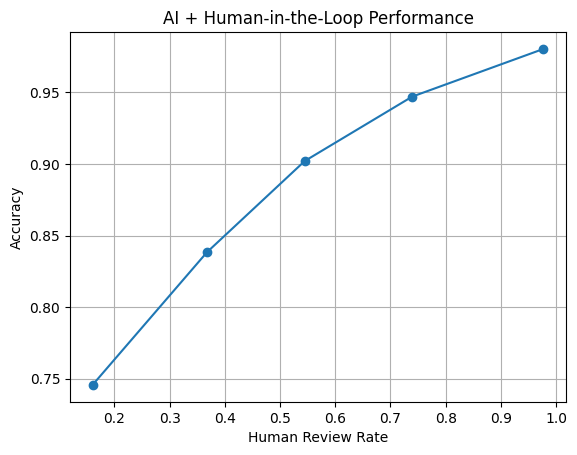

In [43]:
taus, review_rates, accuracies = zip(*results)

plt.plot(review_rates, accuracies, marker='o')
plt.xlabel("Human Review Rate")
plt.ylabel("Accuracy")
plt.title("AI + Human-in-the-Loop Performance")
plt.grid(True)
plt.show()

Right now your human_accuracy is fixed (0.95).

In [44]:
import pandas as pd
# Suppose df is your dataset
categorical_cols = ['Name','Occupation','Type_of_Loan','Credit_Mix','Payment_of_Min_Amount','Payment_Behaviour','Credit_Score']

# One-hot encode
df_encoded = pd.get_dummies(df, columns=categorical_cols)

# Check total number of features after encoding
print("Number of features after encoding:", df_encoded.shape[1])

Number of features after encoding: 16439


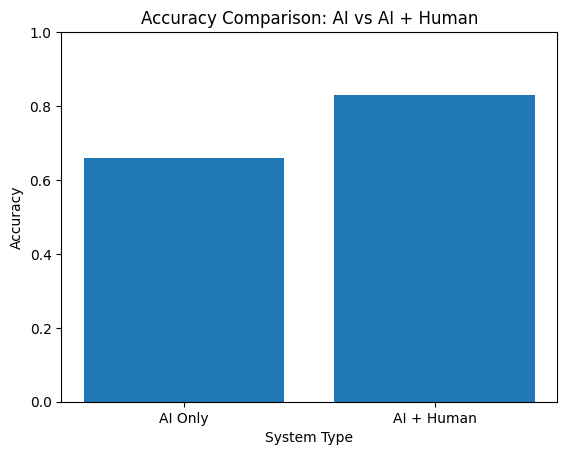

In [48]:
import matplotlib.pyplot as plt

# Example accuracy values
models = ["AI Only", "AI + Human"]
accuracy = [0.66, 0.83]

plt.figure()

plt.bar(models, accuracy)

plt.xlabel("System Type")
plt.ylabel("Accuracy")
plt.title("Accuracy Comparison: AI vs AI + Human")

plt.ylim(0,1)

plt.show()

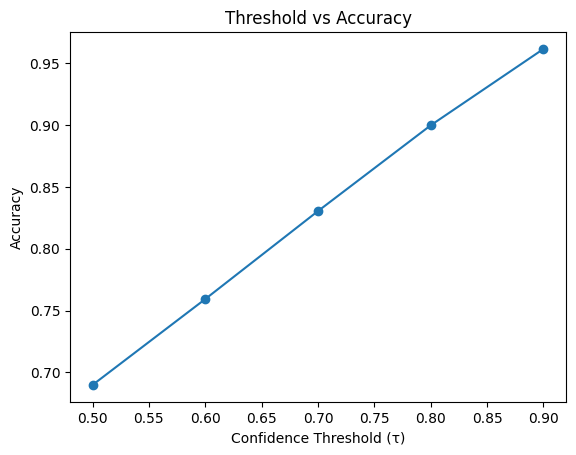

In [49]:
import matplotlib.pyplot as plt

# Example threshold values
threshold = [0.5, 0.6, 0.7, 0.8, 0.9]

# Example accuracy results
accuracy = [0.6898, 0.7593, 0.8305, 0.8999, 0.9617]

plt.figure()

plt.plot(threshold, accuracy, marker='o')

plt.xlabel("Confidence Threshold (τ)")
plt.ylabel("Accuracy")
plt.title("Threshold vs Accuracy")

plt.show()

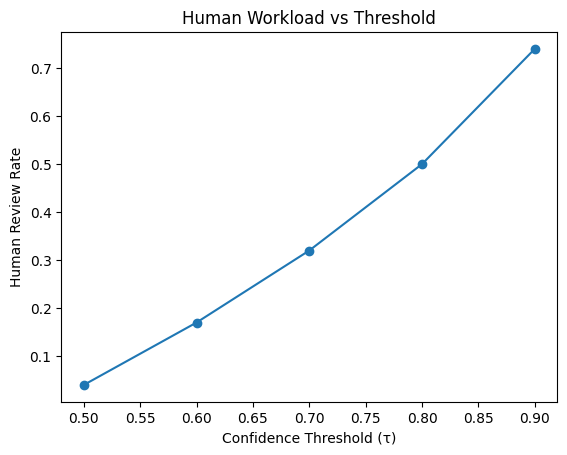

In [50]:
import matplotlib.pyplot as plt

threshold = [0.5, 0.6, 0.7, 0.8, 0.9]

human_review_rate = [0.04, 0.17, 0.32, 0.50, 0.74]

plt.figure()

plt.plot(threshold, human_review_rate, marker='o')

plt.xlabel("Confidence Threshold (τ)")
plt.ylabel("Human Review Rate")
plt.title("Human Workload vs Threshold")

plt.show()

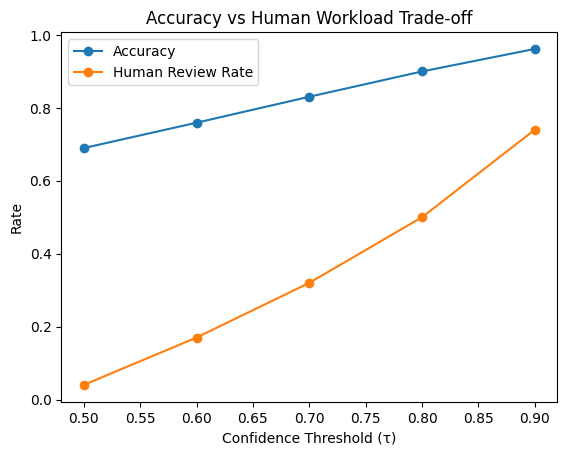

In [51]:
import matplotlib.pyplot as plt

threshold = [0.5,0.6,0.7,0.8,0.9]
accuracy = [0.6898, 0.7593, 0.8305, 0.8999, 0.9617]
human_review_rate = [0.04, 0.17, 0.32, 0.50, 0.74]

plt.figure()

plt.plot(threshold, accuracy, marker='o', label="Accuracy")
plt.plot(threshold, human_review_rate, marker='o', label="Human Review Rate")

plt.xlabel("Confidence Threshold (τ)")
plt.ylabel("Rate")
plt.title("Accuracy vs Human Workload Trade-off")

plt.legend()

plt.show()